Solved State: [1, 5, 2, 0, 7, 0, 4, 6] with 1 attacks.


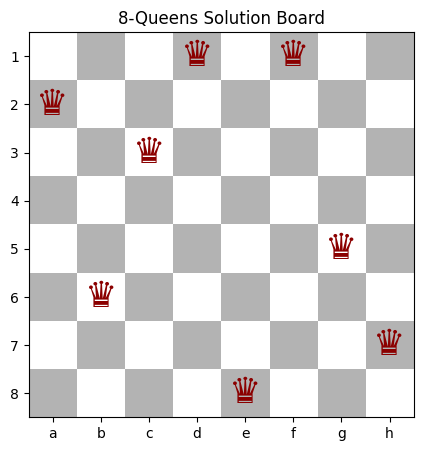

In [7]:
import random
import math
import matplotlib.pyplot as plt
import numpy as np

# 1. Simple helper to calculate attacking pairs
def get_attacks(state):
    attacks = 0
    for i in range(len(state)):
        for j in range(i + 1, len(state)):
            if state[i] == state[j] or abs(state[i] - state[j]) == abs(i - j):
                attacks += 1
    return attacks

# 2. Simulated Annealing
def solve_8queens():
    state = [random.randint(0, 7) for _ in range(8)]
    cost = get_attacks(state)
    T = 10.0
    decay = 0.95

    while T > 0.01 and cost > 0:
        # Pick a random column and change its queen's row
        new_state = list(state)
        col = random.randint(0, 7)
        new_state[col] = random.randint(0, 7)

        new_cost = get_attacks(new_state)
        dE = new_cost - cost

        # Accept if better, or probabilistically if worse
        if dE < 0 or random.random() < math.exp(-dE / T):
            state = new_state
            cost = new_cost

        T *= decay
    return state, cost

# Solve and plot
solution, attacks = solve_8queens()
print(f"Solved State: {solution} with {attacks} attacks.")

# Plot the board
board = np.indices((8, 8)).sum(axis=0) % 2
plt.figure(figsize=(5, 5))
plt.imshow(board, cmap='binary', alpha=0.3)
for col, row in enumerate(solution):
    plt.text(col, row, '♛', fontsize=26, ha='center', va='center', color='darkred')
plt.xticks(range(8), [chr(97 + i) for i in range(8)])
plt.yticks(range(8), range(1, 9))
plt.title("8-Queens Solution Board")
plt.show()